# 05 — H2: Real decarbonization, lower output or higher prices?

**H2:** The relative decline in carbon intensity reflects lower emissions per unit of real output,
rather than higher output prices or reduced production.

Carbon intensity can fall through three channels. Because
$\ln(CI) = \ln(E) - \ln(R^{nom})$ and $\ln(R^{nom}) = \ln(R^{real}) + \ln(P)$:

| Channel | Emissions $E$ | Real revenue $R^{real}$ | Real intensity $E/R^{real}$ |
|---|---|---|---|
| Higher output prices | unchanged | unchanged | unchanged |
| Reduced production | down | down | unchanged |
| **Real decarbonization (H2)** | down | ~unchanged | **down** |

Each outcome is estimated with the same TWFE DiD as H1 on the **industry sample** (NACE 05-39),
where sector producer price indices (Eurostat; ONS for the UK; 2021 = 100) are available.
Because the EDA showed borderline pre-trends for real intensity, every model is also estimated
after removing firm-specific linear pre-trends, and the event study is complemented by
relative-magnitude bounds in the spirit of Rambachan and Roth (2023).

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
import sample as S

TAB, FIG = Path("output/tables"), Path("output/figures")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
VC = {"CRV1": "ric"}

p = S.load_panel()
h2 = S.industry_sample(p)
h2["post_high"] = h2.post * h2.high_exposure
h2["ln_revenue"] = np.log(h2.revenue.where(h2.revenue > 0))
h2["ln_price"] = np.log(h2.ppi / 100)
h2["ln_ci"] = h2.ln_emissions - h2.ln_revenue
h2["ln_scope1"] = np.log(h2.scope1.where(h2.scope1 > 0))
h2["ln_scope2"] = np.log(h2.scope2.where(h2.scope2 > 0))
print(f"H2 sample: {h2.ric.nunique()} firms, {len(h2)} firm-years, high exposure: {h2.drop_duplicates('ric').high_exposure.sum()}")

OUT = {"ln_ci": "ln(CO2e / nominal revenue)", "ln_emissions": "ln(Scope 1+2 emissions)",
       "ln_revenue": "ln(nominal revenue)", "ln_real_revenue": "ln(real revenue)",
       "ln_price": "ln(sector price index)", "ln_real_ci": "ln(CO2e / real revenue)",
       "ln_scope1": "ln(Scope 1)", "ln_scope2": "ln(Scope 2)"}

H2 sample: 230 firms, 1936 firm-years, high exposure: 115


## 1. Decomposition: DiD on each component

In [2]:
def did(df, y):
    m = pf.feols(f"{y} ~ post_high | ric + fyear", data=df.dropna(subset=[y]), vcov=VC)
    t = m.tidy().loc["post_high"]
    return m, {"outcome": OUT[y], "var": y, "coef": t["Estimate"], "se": t["Std. Error"], "p": t["Pr(>|t|)"],
               "ci_low": t["2.5%"], "ci_high": t["97.5%"], "pct": 100 * (np.exp(t["Estimate"]) - 1),
               "N": m._N, "firms": df.dropna(subset=[y]).ric.nunique()}

comp = ["ln_ci", "ln_emissions", "ln_revenue", "ln_price", "ln_real_revenue", "ln_real_ci"]
fits, rows = {}, []
for y in comp:
    m, r = did(h2, y); fits[y] = m; rows.append(r)
dec = pd.DataFrame(rows)
dec.to_csv(TAB / "h2_decomposition.csv", index=False)
pf.etable([fits[y] for y in comp], type="tex", file_name=str(TAB / "h2_decomposition.tex"),
          labels={"post_high": "Post $\\times$ High exposure", **OUT})
dec[["outcome", "coef", "se", "p", "pct", "N", "firms"]]

,outcome,coef,se,p,pct,N,firms
0,ln(CO2e / nominal revenue),-0.276879,0.080640,7.070171e-04,-24.185380,1936,230
1,ln(Scope 1+2 emissions),-0.255080,0.081236,1.912014e-03,-22.514552,1936,230
2,ln(nominal revenue),0.021799,0.034323,5.259894e-01,2.203833,1936,230
3,ln(sector price index),0.187884,0.026306,1.210454e-11,20.669410,1936,230
4,ln(real revenue),-0.166085,0.039796,4.263967e-05,-15.302617,1936,230
5,ln(CO2e / real revenue),-0.088995,0.081462,2.757746e-01,-8.514945,1936,230


**Accounting check:** `ln_ci` = `ln_emissions` - `ln_revenue` and `ln_real_ci` = `ln_emissions` - `ln_real_revenue`
hold identically in the data, so on a common sample the coefficients add up. Small gaps come from
firm-years where one component is missing.

In [3]:
d = dec.set_index("var").coef
print(f"ln_emissions - ln_revenue      = {d.ln_emissions - d.ln_revenue:+.3f}   vs ln_ci      {d.ln_ci:+.3f}")
print(f"ln_emissions - ln_real_revenue = {d.ln_emissions - d.ln_real_revenue:+.3f}   vs ln_real_ci {d.ln_real_ci:+.3f}")

ln_emissions - ln_revenue      = -0.277   vs ln_ci      -0.277
ln_emissions - ln_real_revenue = -0.089   vs ln_real_ci -0.089


## 2. Scope 1 vs. Scope 2
The gas price shock mainly affects fuel burned on site (Scope 1); Scope 2 (purchased electricity)
also reflects changes in the grid mix, including the 2022 gas-to-coal switch in power generation.

In [4]:
rows = [did(h2, y)[1] for y in ["ln_scope1", "ln_scope2"]]
sc = pd.DataFrame(rows); sc.to_csv(TAB / "h2_scopes.csv", index=False)
sc[["outcome", "coef", "se", "p", "pct", "N", "firms"]]

C:\_repos\energy-prices-decarbonization\.venv\Lib\site-packages\pyfixest\estimation\formula\model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(
C:\_repos\energy-prices-decarbonization\.venv\Lib\site-packages\pyfixest\estimation\formula\model_matrix.py:151: UserWarning: 1 singleton fixed effect(s) dropped from the model.
  warnings.warn(


,outcome,coef,se,p,pct,N,firms
0,ln(Scope 1),-0.277787,0.096522,0.004383,-24.254194,1882,230
1,ln(Scope 2),-0.237954,0.077737,0.002470,-21.176067,1874,230


## 3. Event studies for the H2 outcomes

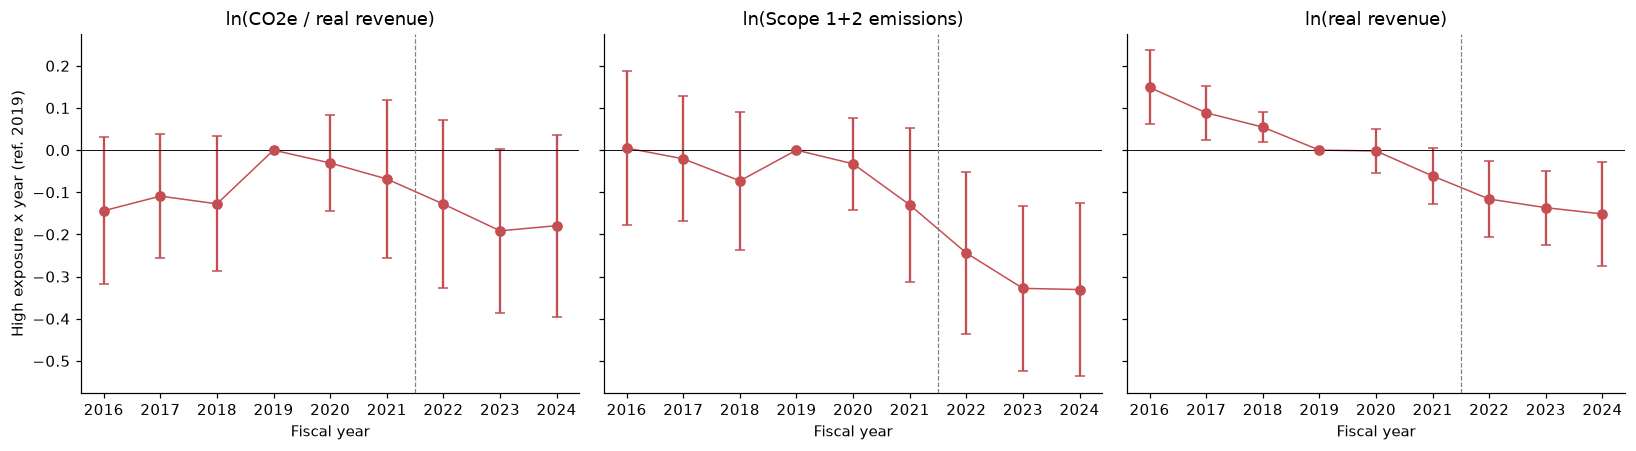

ln_real_ci            ln_emissions            ln_real_revenue           
       Estimate Std. Error     Estimate Std. Error        Estimate Std. Error
year                                                                         
2016     -0.144      0.089        0.005      0.093           0.149      0.044
2017     -0.109      0.075       -0.021      0.075           0.089      0.032
2018     -0.127      0.081       -0.073      0.083           0.055      0.018
2019      0.000      0.000        0.000      0.000           0.000      0.000
2020     -0.031      0.057       -0.033      0.055          -0.002      0.027
2021     -0.068      0.095       -0.130      0.092          -0.061      0.034
2022     -0.128      0.101       -0.244      0.098          -0.116      0.045
2023     -0.191      0.098       -0.328      0.099          -0.136      0.045
2024     -0.179      0.110       -0.331      0.104          -0.151      0.062

In [5]:
def event_study(df, y):
    m = pf.feols(f"{y} ~ i(fyear, high_exposure, ref=2019) | ric + fyear", data=df.dropna(subset=[y]), vcov=VC)
    t = m.tidy().reset_index(); t["year"] = t["Coefficient"].str.extract(r"(\d{4})").astype(int)
    t = pd.concat([t, pd.DataFrame([{"year": 2019, "Estimate": 0.0, "Std. Error": 0.0, "2.5%": 0.0, "97.5%": 0.0}])])
    return m, t.sort_values("year")

es = {y: event_study(h2, y) for y in ["ln_real_ci", "ln_emissions", "ln_real_revenue"]}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (y, (m, t)) in zip(axs, es.items()):
    ax.errorbar(t.year, t.Estimate, yerr=[t.Estimate - t["2.5%"], t["97.5%"] - t.Estimate], fmt="o", capsize=3, color="#C44E52")
    ax.plot(t.year, t.Estimate, color="#C44E52", lw=1)
    ax.axhline(0, color="k", lw=0.6); ax.axvline(2021.5, color="grey", ls="--", lw=0.8)
    ax.set_title(OUT[y]); ax.set_xlabel("Fiscal year")
axs[0].set_ylabel("High exposure x year (ref. 2019)")
fig.tight_layout(); fig.savefig(FIG / "h2_event_studies.pdf"); plt.show()
pd.concat({y: t.set_index("year")[["Estimate", "Std. Error"]] for y, (m, t) in es.items()}, axis=1).round(3)

### Joint pre-trend tests

In [6]:
from scipy import stats

def pretrend_test(m, years):
    c = m.coef(); idx = [i for i, n in enumerate(c.index) if any(str(y) in n for y in years)]
    b = c.values[idx]; V = m._vcov[np.ix_(idx, idx)]
    F = float(b @ np.linalg.inv(V) @ b) / len(idx)
    return F, 1 - stats.f.cdf(F, len(idx), h2.ric.nunique() - 1)

rows = []
for y, (m, t) in es.items():
    F1, p1 = pretrend_test(m, [2016, 2017, 2018, 2020, 2021]); F2, p2 = pretrend_test(m, [2016, 2017, 2018])
    rows.append({"outcome": OUT[y], "F_all_pre": F1, "p_all_pre": p1, "F_2016_2018": F2, "p_2016_2018": p2})
ptt = pd.DataFrame(rows); ptt.to_csv(TAB / "h2_pretrend_tests.csv", index=False)
ptt

,outcome,F_all_pre,p_all_pre,F_2016_2018,p_2016_2018
0,ln(CO2e / real revenue),0.677502,0.640910,1.041489,0.374960
1,ln(Scope 1+2 emissions),0.564104,0.727469,0.421990,0.737404
2,ln(real revenue),4.784413,0.000353,4.751077,0.003106


## 4. Robustness to pre-trends
### 4a. Removing firm-specific linear pre-trends
For each firm, a linear trend is fitted on 2016-2019 (pre-shock, pre-COVID; at least 3 years) and
extrapolated to all years; the DiD is then estimated on the detrended outcome. This removes any
pre-existing divergence that would otherwise be attributed to the shock.

In [7]:
def detrend(df, y, years=range(2016, 2020), min_obs=3):
    out = df.copy(); out[f"{y}_dt"] = np.nan
    for ric, g in df.dropna(subset=[y]).groupby("ric"):
        pre = g[g.fyear.isin(years)]
        if pre.fyear.nunique() >= min_obs:
            a, b = np.polyfit(pre.fyear, pre[y], 1)
            idx = g.index
            out.loc[idx, f"{y}_dt"] = g[y] - (a * g.fyear + b)
    return out

rows = []
for y in ["ln_real_ci", "ln_emissions", "ln_real_revenue", "ln_ci"]:
    dt = detrend(h2, y)
    m = pf.feols(f"{y}_dt ~ post_high | ric + fyear", data=dt.dropna(subset=[f"{y}_dt"]), vcov=VC)
    t = m.tidy().loc["post_high"]
    rows.append({"outcome": OUT[y], "coef_detrended": t["Estimate"], "se": t["Std. Error"], "p": t["Pr(>|t|)"],
                 "N": m._N, "firms": dt.dropna(subset=[f"{y}_dt"]).ric.nunique(),
                 "coef_baseline": dec.set_index("var").coef.get(y, np.nan)})
dtr = pd.DataFrame(rows); dtr.to_csv(TAB / "h2_detrended.csv", index=False)
dtr

,outcome,coef_detrended,se,p,N,firms,coef_baseline
0,ln(CO2e / real revenue),-0.240527,0.131867,0.069664,1734,198,-0.088995
1,ln(Scope 1+2 emissions),-0.235735,0.136609,0.085985,1734,198,-0.255080
2,ln(real revenue),0.004793,0.063871,0.940260,1734,198,-0.166085
3,ln(CO2e / nominal revenue),-0.323367,0.129156,0.013103,1734,198,-0.276879


### 4b. Relative-magnitude bounds (Rambachan and Roth 2023, simplified)
Assume that post-2022 violations of parallel trends are at most $\bar M$ times as large as the
largest pre-period deviation (2016-2021, relative to 2019). For the average post-2022 effect
$\hat\theta$ the bounds are $\hat\theta \pm \bar M \cdot \max_{pre} |\hat\beta_k|$, widened by the
95% confidence interval. If zero lies outside the bounds for $\bar M = 1$, the conclusion survives
pre-trend violations as large as those observed before the shock.

*Note:* this is a transparent simplification of the HonestDiD relative-magnitude restriction; the
exact procedure accounts for the joint covariance of all coefficients.

In [8]:
def rm_bounds(m, t, Mbars=(0, 0.5, 1, 1.5, 2)):
    post = t[t.year >= 2022]; pre = t[(t.year < 2022) & (t.year != 2019)]
    names = [n for n in m.coef().index if any(str(y) in n for y in post.year)]
    idx = [list(m.coef().index).index(n) for n in names]
    w = np.ones(len(idx)) / len(idx)
    theta = float(w @ m.coef().values[idx]); se = float(np.sqrt(w @ m._vcov[np.ix_(idx, idx)] @ w))
    maxpre = pre.Estimate.abs().max()
    return pd.DataFrame([{"Mbar": M, "theta": theta, "lower": theta - M * maxpre - 1.96 * se,
                          "upper": theta + M * maxpre + 1.96 * se} for M in Mbars])

rmb = pd.concat({OUT[y]: rm_bounds(m, t) for y, (m, t) in es.items()}).reset_index(level=0).rename(columns={"level_0": "outcome"})
# H1 outcome on the H1 sample for comparison
h1 = S.main_sample(p); h1["post_high"] = h1.post * h1.high_exposure
m_h1, t_h1 = event_study(h1, "ln_ci")
rmb = pd.concat([rmb, rm_bounds(m_h1, t_h1).assign(outcome="H1: ln(CO2e / nominal revenue), H1 sample")])
rmb.to_csv(TAB / "rr_bounds.csv", index=False)
rmb.pivot(index="Mbar", columns="outcome", values=["lower", "upper"]).round(3)

lower                          \
outcome H1: ln(CO2e / nominal revenue), H1 sample ln(CO2e / real revenue)   
Mbar                                                                        
0.0                                        -0.407                  -0.361   
0.5                                        -0.448                  -0.433   
1.0                                        -0.490                  -0.505   
1.5                                        -0.531                  -0.576   
2.0                                        -0.572                  -0.648   

                                                  \
outcome ln(Scope 1+2 emissions) ln(real revenue)   
Mbar                                               
0.0                      -0.492           -0.227   
0.5                      -0.557           -0.302   
1.0                      -0.622           -0.376   
1.5                      -0.687           -0.451   
2.0                      -0.752           -0.525   

                                            upper                          \
outcome H1: ln(CO2e / nominal revenue), H1 sample ln(CO2e / real revenue)   
Mbar                                                                        
0.0                                        -0.053                   0.028   
0.5                                        -0.012                   0.100   
1.0                                         0.029                   0.172   
1.5                                         0.071                   0.244   
2.0                                         0.112                   0.316   

                                                  
outcome ln(Scope 1+2 emissions) ln(real revenue)  
Mbar                                              
0.0                      -0.110           -0.042  
0.5                      -0.045            0.032  
1.0                       0.020            0.107  
1.5                       0.085            0.181  
2.0                       0.150            0.256

## 5. Summary

In [9]:
d = dec.set_index("var")
for y in comp:
    print(f"{OUT[y]:32s} beta = {d.loc[y,'coef']:+.3f} (p = {d.loc[y,'p']:.3f})  -> {d.loc[y,'pct']:+.1f}%")
print("\nDetrended:"); print(dtr[["outcome", "coef_detrended", "p"]].round(3).to_string(index=False))

ln(CO2e / nominal revenue)       beta = -0.277 (p = 0.001)  -> -24.2%
ln(Scope 1+2 emissions)          beta = -0.255 (p = 0.002)  -> -22.5%
ln(nominal revenue)              beta = +0.022 (p = 0.526)  -> +2.2%
ln(sector price index)           beta = +0.188 (p = 0.000)  -> +20.7%
ln(real revenue)                 beta = -0.166 (p = 0.000)  -> -15.3%
ln(CO2e / real revenue)          beta = -0.089 (p = 0.276)  -> -8.5%

Detrended:
                   outcome  coef_detrended     p
   ln(CO2e / real revenue)          -0.241 0.070
   ln(Scope 1+2 emissions)          -0.236 0.086
          ln(real revenue)           0.005 0.940
ln(CO2e / nominal revenue)          -0.323 0.013
